# Automated Identification of Gait Abnormalities

## Final Training Notebook

**Final approach:** MediaPipe pose keypoints + frame-to-frame velocity + LSTM  
**Dataset:** GAVD-derived 319 usable gait sequences  
**Classes:** Normal (0), Abnormal (1)

This notebook contains the final training pipeline and the completed experimental results. Earlier exploratory experiments are summarized where useful, but duplicate/obsolete cells have been removed for clarity.


## 1. Dataset Upload

In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print("-", filename)

print("\nExpected file: gait_dataset_319.zip")


## 2. Extract Dataset

In [ ]:
import zipfile
import os

zip_path = "/content/gait_dataset_319.zip"
extract_path = "/content/gait_dataset_319"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")
print("Files:", os.listdir(extract_path))


Extraction complete!
Files: ['labels.csv', 'keypoints']


## 3. Prepare Pose Sequences

In [ ]:
import os
import numpy as np
import pandas as pd

DATA_DIR = "/content/gait_dataset_319"
KEYPOINT_DIR = os.path.join(DATA_DIR, "keypoints")
LABELS_FILE = os.path.join(DATA_DIR, "labels.csv")

df = pd.read_csv(LABELS_FILE)

X = []
y = []
used_ids = []

TARGET_FRAMES = 100

def resize_sequence(sequence, target_frames=100):
    """Temporally interpolate a pose sequence to a fixed number of frames."""
    old_frames = sequence.shape[0]

    if old_frames == target_frames:
        return sequence

    old_indices = np.linspace(0, 1, old_frames)
    new_indices = np.linspace(0, 1, target_frames)

    resized = np.zeros(
        (target_frames, sequence.shape[1], sequence.shape[2])
    )

    for joint in range(sequence.shape[1]):
        for coord in range(sequence.shape[2]):
            resized[:, joint, coord] = np.interp(
                new_indices,
                old_indices,
                sequence[:, joint, coord]
            )

    return resized

for _, row in df.iterrows():
    video_id = row["video_id"]
    path = os.path.join(KEYPOINT_DIR, video_id + ".npy")

    if not os.path.exists(path):
        continue

    sequence = np.load(path)
    sequence = resize_sequence(sequence, TARGET_FRAMES)

    # 33 landmarks × 3 coordinates = 99 position features
    sequence = sequence.reshape(TARGET_FRAMES, -1)

    X.append(sequence)

    # normal = 0, abnormal = 1
    y.append(1 if row["label"] == "abnormal" else 0)

    used_ids.append(video_id)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("Dataset prepared successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Normal samples:", np.sum(y == 0))
print("Abnormal samples:", np.sum(y == 1))
print("Total samples:", len(y))


Dataset prepared successfully!
X shape: (319, 100, 99)
y shape: (319,)
Normal samples: 156
Abnormal samples: 163
Total samples: 319


### Dataset summary

- **319 usable sequences**
- **100 frames per sequence**
- **33 pose landmarks**
- **3 coordinates per landmark**
- **99 position features per frame**
- Normal = 0
- Abnormal = 1


## 4. Baseline Experiment — Position-Only LSTM

The position-only LSTM was retained as a baseline for comparison.

**Completed baseline test results:**

| Metric | Position-only LSTM |
|---|---:|
| Accuracy | 68.75% |
| Precision | 63.64% |
| Recall | 87.50% |
| F1 Score | 73.68% |

Confusion matrix:

```text
[[8, 8],
 [2, 14]]
```

This baseline motivated the addition of temporal motion information through frame-to-frame velocity.


## 5. Train / Validation / Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# 80% training, 10% validation, 10% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nClass distribution:")
print("Train      - Normal:", sum(y_train == 0),
      "Abnormal:", sum(y_train == 1))
print("Validation - Normal:", sum(y_val == 0),
      "Abnormal:", sum(y_val == 1))
print("Test       - Normal:", sum(y_test == 0),
      "Abnormal:", sum(y_test == 1))


Train: (255, 100, 99) (255,)
Validation: (32, 100, 99) (32,)
Test: (32, 100, 99) (32,)

Class distribution:
Train     - Normal: 125 Abnormal: 130
Validation- Normal: 15 Abnormal: 17
Test      - Normal: 16 Abnormal: 16


## 6. Proposed Method — Position + Velocity Features

In [ ]:
# X shape = (319, 100, 99)

# Calculate frame-to-frame movement velocity
velocity = np.diff(X, axis=1)

# Keep the same number of frames by padding the first frame with zeros
velocity = np.concatenate(
    [np.zeros((X.shape[0], 1, X.shape[2])), velocity],
    axis=1
)

# Combine position + velocity
X_motion = np.concatenate([X, velocity], axis=2)

print("Position shape:", X.shape)
print("Velocity shape:", velocity.shape)
print("Position + velocity shape:", X_motion.shape)


Position shape: (319, 100, 99)
Velocity shape: (319, 100, 99)
Position + velocity shape: (319, 100, 198)


### Feature representation

Each frame contains:

- **99 position features:** 33 landmarks × 3 coordinates
- **99 velocity features:** frame-to-frame change of those coordinates
- **198 total features per frame**

The sequence therefore has the shape **(100, 198)** before being passed to the LSTM.


## 7. Split Motion-Feature Dataset

In [ ]:
from sklearn.model_selection import train_test_split

Xm_train, Xm_temp, ym_train, ym_temp = train_test_split(
    X_motion,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

Xm_val, Xm_test, ym_val, ym_test = train_test_split(
    Xm_temp,
    ym_temp,
    test_size=0.50,
    stratify=ym_temp,
    random_state=42
)

print("Motion-feature split:")
print("Train:", Xm_train.shape, ym_train.shape)
print("Validation:", Xm_val.shape, ym_val.shape)
print("Test:", Xm_test.shape, ym_test.shape)

print("\nClass distribution:")
print("Train      - Normal:", sum(ym_train == 0),
      "Abnormal:", sum(ym_train == 1))
print("Validation - Normal:", sum(ym_val == 0),
      "Abnormal:", sum(ym_val == 1))
print("Test       - Normal:", sum(ym_test == 0),
      "Abnormal:", sum(ym_test == 1))


Motion-feature split:
Train: (255, 100, 198) (255,)
Validation: (32, 100, 198) (32,)
Test: (32, 100, 198) (32,)

Class distribution:
Train      - Normal: 125 Abnormal: 130
Validation - Normal: 15 Abnormal: 17
Test       - Normal: 16 Abnormal: 16


## 8. Position + Velocity LSTM Architecture

In [39]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

model_motion = Sequential([
    Input(shape=(100, 198)),

    LSTM(64, return_sequences=True),
    Dropout(0.3),

    LSTM(32),
    Dropout(0.3),

    Dense(16, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model_motion.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_motion.summary()


Epoch 1/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.5412 - loss: 0.6859 - val_accuracy: 0.6562 - val_loss: 0.6717 - learning_rate: 0.0010
Epoch 2/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5961 - loss: 0.6687 - val_accuracy: 0.6250 - val_loss: 0.6314 - learning_rate: 0.0010
Epoch 3/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5922 - loss: 0.6831 - val_accuracy: 0.6250 - val_loss: 0.6432 - learning_rate: 0.0010
Epoch 4/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6314 - loss: 0.6392 - val_accuracy: 0.6250 - val_loss: 0.6342 - learning_rate: 0.0010
Epoch 5/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6353 - loss: 0.6258 - val_accuracy: 0.7188 - val_loss: 0.6131 - learning_rate: 0.0010
Epoch 6/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6667 - loss: 0.6183 - val_accuracy: 0.6250 - val_loss: 0.6240 - learning_rate: 0.0010
Epoch 7/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6431 - loss: 0.6374 - val_acc

### Training configuration

- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 16
- Maximum epochs: 60
- Early stopping on validation loss
- Learning-rate reduction on validation-loss plateau
- Balanced class weights


In [ ]:
# Balanced class weights
classes = np.unique(ym_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=ym_train
)

class_weights_motion = dict(zip(classes, weights))

early_stopping_motion = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_motion = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history_motion = model_motion.fit(
    Xm_train,
    ym_train,
    validation_data=(Xm_val, ym_val),
    epochs=60,
    batch_size=16,
    class_weight=class_weights_motion,
    callbacks=[early_stopping_motion, reduce_lr_motion],
    verbose=1
)

print("\nMotion-feature model training completed!")
print("Epochs trained:", len(history_motion.history["loss"]))


## 9. Final Test Evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predictions on the untouched test set
ym_prob = model_motion.predict(Xm_test)
ym_pred = (ym_prob >= 0.5).astype(int).ravel()

accuracy_motion = accuracy_score(ym_test, ym_pred)
precision_motion = precision_score(ym_test, ym_pred)
recall_motion = recall_score(ym_test, ym_pred)
f1_motion = f1_score(ym_test, ym_pred)

print("===== MOTION-FEATURE TEST RESULTS =====")
print(f"Accuracy : {accuracy_motion * 100:.2f}%")
print(f"Precision: {precision_motion * 100:.2f}%")
print(f"Recall   : {recall_motion * 100:.2f}%")
print(f"F1 Score : {f1_motion * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(ym_test, ym_pred))

print("\nClassification Report:")
print(classification_report(
    ym_test,
    ym_pred,
    target_names=["Normal", "Abnormal"]
))


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 512ms/step
===== MOTION-FEATURE TEST RESULTS =====
Accuracy : 78.12%
Precision: 76.47%
Recall   : 81.25%
F1 Score : 78.79%

Confusion Matrix:
[[12  4]
 [ 3 13]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.80      0.75      0.77        16
    Abnormal       0.76      0.81      0.79        16

    accuracy                           0.78        32
   macro avg       0.78      0.78      0.78        32
weighted avg       0.78      0.78      0.78        32



### Final result

**Position + Velocity LSTM**

- **Accuracy: 78.12%**
- **Precision: 76.47%**
- **Recall: 81.25%**
- **F1 Score: 78.79%**

Confusion matrix:

```text
[[12, 4],
 [ 3, 13]]
```


## 10. Training Curves

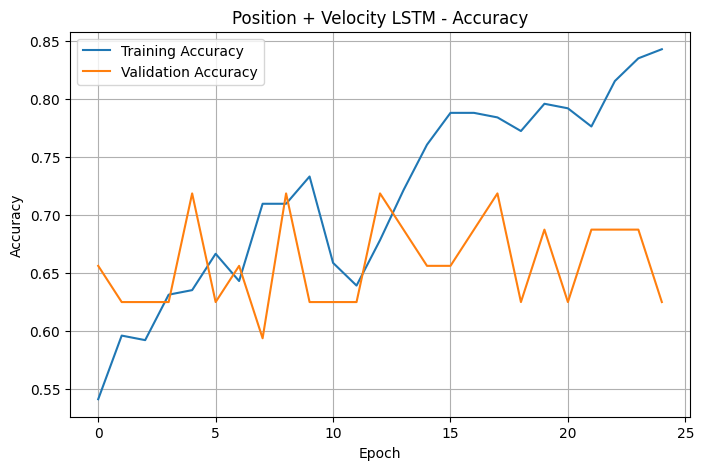

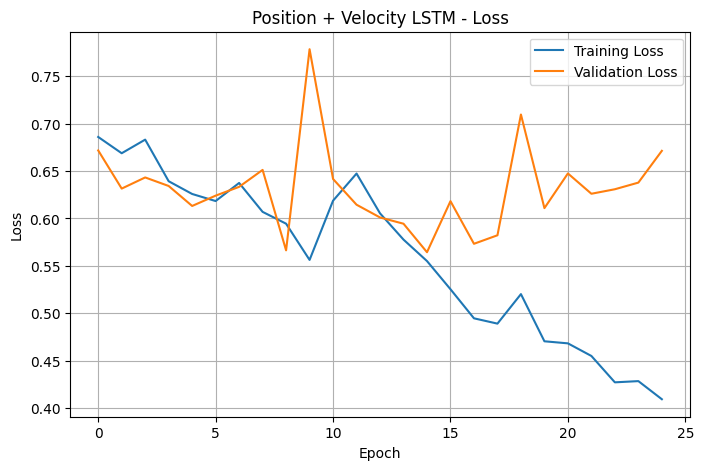

In [ ]:
import matplotlib.pyplot as plt

# Training vs Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history_motion.history["accuracy"], label="Training Accuracy")
plt.plot(history_motion.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Position + Velocity LSTM - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Training vs Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history_motion.history["loss"], label="Training Loss")
plt.plot(history_motion.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Position + Velocity LSTM - Loss")
plt.legend()
plt.grid(True)
plt.show()


## 11. Confusion Matrix

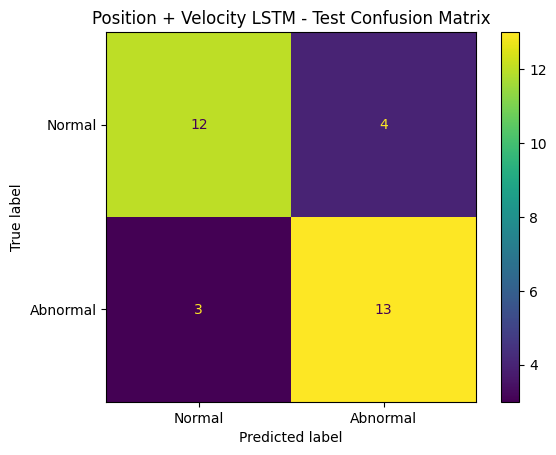

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_motion = confusion_matrix(ym_test, ym_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_motion,
    display_labels=["Normal", "Abnormal"]
)

disp.plot()
plt.title("Position + Velocity LSTM - Test Confusion Matrix")
plt.show()


## 12. Model Comparison

| Model | Accuracy | Precision | Recall | F1 Score |
|---|---:|---:|---:|---:|
| Position-only LSTM | 68.75% | 63.64% | 87.50% | 73.68% |
| **Position + Velocity LSTM** | **78.12%** | **76.47%** | **81.25%** | **78.79%** |

The final model improves test accuracy by **9.37 percentage points** and F1 score by **5.11 percentage points** over the position-only baseline.


## 13. Save and Verify Final Model

In [ ]:
model_motion.save("/content/gait_lstm_motion_319.keras")

print("Final motion-feature model saved successfully!")


Best motion-feature model saved successfully!


In [ ]:
import os

model_path = "/content/gait_lstm_motion_319.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print(
        "Model size:",
        round(os.path.getsize(model_path) / (1024 * 1024), 2),
        "MB"
    )


Model exists: True
Model size: 0.96 MB


### Final model specification

**Saved file:** `gait_lstm_motion_319.keras`

**Input shape:** `(100, 198)`  
**Output:** Binary probability — Normal / Abnormal

This is the model used by the local Streamlit application.


## 14. Download Final Model

In [ ]:
from google.colab import files

files.download("/content/gait_lstm_motion_319.keras")


## Final Summary

The final pipeline is:

**GAVD gait sequences → MediaPipe pose keypoints → 100-frame temporal resizing → position + frame-to-frame velocity → 198 features/frame → LSTM → Normal/Abnormal classification**

The final held-out test performance is **78.12% accuracy** with **78.79% F1 score**.
